**Projeto:** PyAnalytics — UFSC Araranguá  
**Tema:** Mortalidade Evitável e Desigualdades Sociais  

Objetivo da Sprint:
Carregar a base de dados unificada de Santa Catarina diretamente do diretório processado do repositório, isolar os registros do município de Araranguá (`CODMUNRES == 420140`) e realizar a leitura inicial das variáveis estruturais disponíveis (`CAUSABAS`, `IDADE`, `SEXO`, `RACACOR`, `ESC2010`).

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

#Santa Catarina
df = pd.read_csv('../data/processed/sim_sc_processado.csv')

#Araranguá (Código IBGE: 420140)
df_ararangua = df[df['CODMUNRES'].astype(str).str.contains('420140', na=False)]

print(f"Total de registros para Araranguá: {len(df_ararangua)}")

C:\Users\goula\AppData\Local\Temp\ipykernel_15612\1733608085.py:8: DtypeWarning: Columns (0: DTOBITO, 1: DTNASC, 2: RACACOR, 3: ESC, 4: IDADEMAE, 5: ESCMAE, 6: GESTACAO, 7: LINHAA, 8: LINHAB, 9: LINHAC, 10: LINHAD, 11: LINHAII, 12: TPPOS, 13: CAUSABAS_O, 14: CB_PRE, 15: CAUSAMAT, 16: STCODIFICA, 17: CODIFICADO, 18: VERSAOSIST, 19: ATESTADO, 20: FONTES, 21: TPNIVELINV, 22: FONTESINF, 23: CB_ALT, 24: OCUPACAO, 25: FILHVIVOS, 26: FILHMORT) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('../data/processed/sim_sc_processado.csv')


Total de registros para Araranguá: 15608


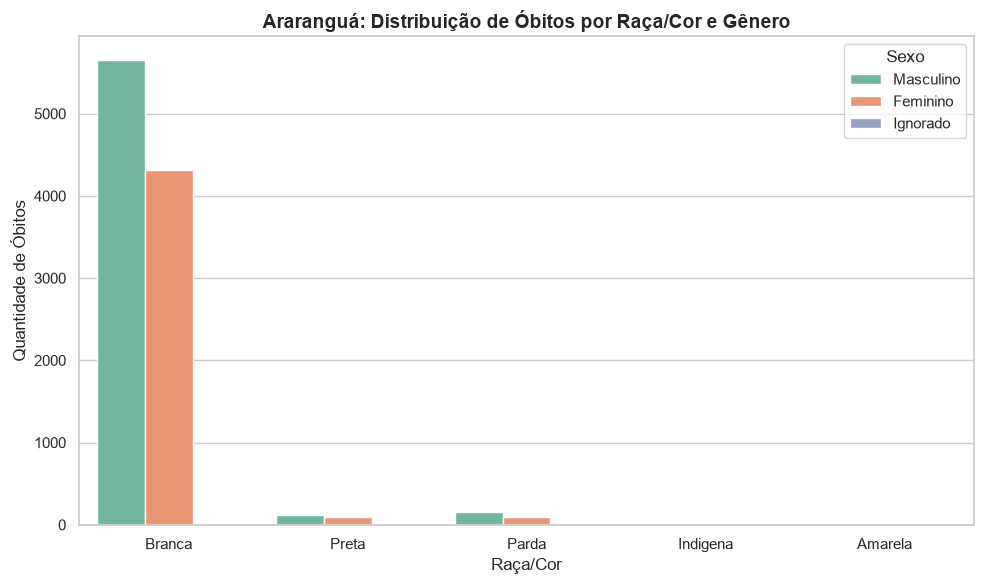

In [ ]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df_ararangua, x='RACACOR', hue='SEXO', palette='Set2')

plt.title('Araranguá: Distribuição de Óbitos por Raça/Cor e Gênero', fontsize=14, fontweight='bold')
plt.xlabel('Raça/Cor', fontsize=12)
plt.ylabel('Quantidade de Óbitos', fontsize=12)
plt.legend(title='Sexo')

plt.tight_layout()
plt.show()

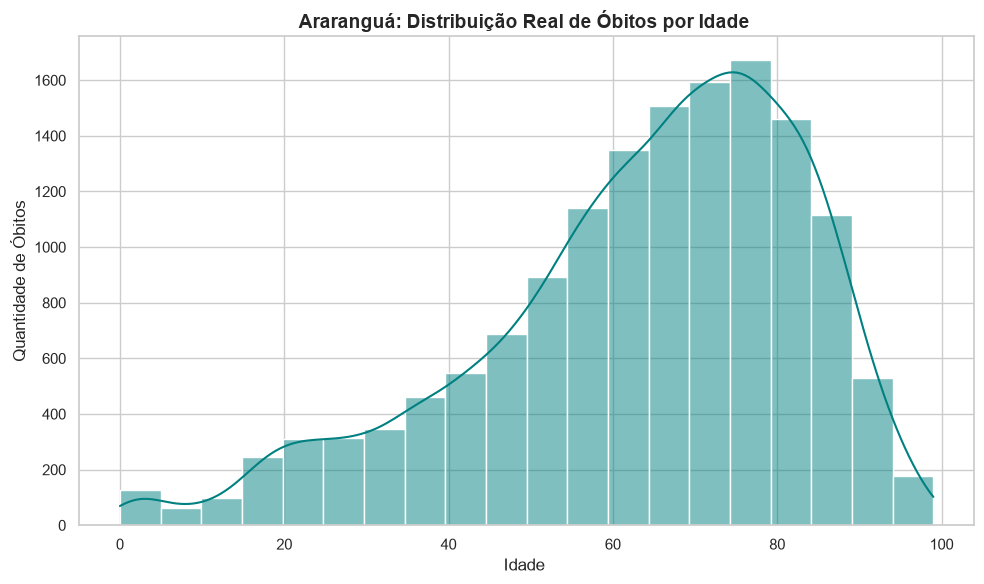

In [ ]:

df_anos = df_ararangua[df_ararangua['IDADE'].astype(str).str.startswith('4', na=False)].copy()

df_anos['IDADE_REAL'] = df_anos['IDADE'].astype(str).str.slice(1).astype(float)

plt.figure(figsize=(10, 6))
sns.histplot(data=df_anos, x='IDADE_REAL', bins=20, kde=True, color='teal')

plt.title('Araranguá: Distribuição de óbitos por idade ', fontsize=14, fontweight='bold')
plt.xlabel('Idade ', fontsize=12)
plt.ylabel('Quantidade de óbitos', fontsize=12)

plt.tight_layout()
plt.show()